# Imports

In [1]:
import subprocess
import os
import glob
import sys
rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)

from rstools import RSoftCircuit

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import linecache
from tqdm import tqdm

# Run scan in wavelength and phase

### Passive tricoupler

In [51]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename, input_config = "Tricoupler_FiberOneInput", 'Center' # offset = (BendOffset+width+TricouplerCoupleSeparation)
filename_root = f'{filename}_{input_config}_RaisedSineSbend'
save_dir = working_dir+f"{filename_root}_scan_Wav_CouplingLength"
filename = f"{filename}.ind"

wav_arr = np.linspace(1.45, 1.65, 51)
length_arr = np.array([278., 308., 338.])

# Make scan save directory if it doesn't exist
os.makedirs(f"{save_dir}\\", exist_ok=True)

for i, wav in tqdm(enumerate(wav_arr), desc='Wavelength loop', position=0, leave=False):
    for length in tqdm(length_arr, desc=f"Coupling length loop (Wavelength: {wav} microns)", position=1, leave=False): 
        # Read in circuit, set probe wavelength
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("TricouplerCoupleLength", length)
        c.write(working_dir+filename)
    
        wav_str = f"{wav:0.3f}".replace(".", "p")
        length_str = f"{length:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_scan_Wav{wav_str}_CouplingLength{length_str}", "wait=0"]
        
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

np.save(f"{save_dir}/{filename_root}_Wav.npy", wav_arr)
np.save(f"{save_dir}/{filename_root}_CouplingLength.npy", length_arr)

Wavelength loop: 0it [00:00, ?it/s]
Coupling length loop (Wavelength: 1.45 microns):   0%|                                           | 0/3 [00:00<?, ?it/s]
Coupling length loop (Wavelength: 1.45 microns): 100%|███████████████████████████████████| 3/3 [01:04<00:00, 21.78s/it]
Wavelength loop: 1it [01:04, 64.97s/it]                                                                                
Coupling length loop (Wavelength: 1.454 microns):   0%|                                          | 0/3 [00:00<?, ?it/s]
Coupling length loop (Wavelength: 1.454 microns):  33%|███████████▎                      | 1/3 [00:22<00:45, 22.57s/it]
Coupling length loop (Wavelength: 1.454 microns):  67%|██████████████████████▋           | 2/3 [00:46<00:23, 23.10s/it]
Coupling length loop (Wavelength: 1.454 microns): 100%|██████████████████████████████████| 3/3 [01:09<00:00, 23.30s/it]
Wavelength loop: 2it [02:14, 67.70s/it]                                                                                
Coup

### Active tricoupler

In [10]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename_root = "Tricoupler_FiberThreeInput"
save_dir = working_dir+f"{filename_root}_scan_Wav_coupleLength"
# wav_arr = np.load(f"{save_dir}/{filename_root}_Wav.npy")
# coupleLength_arr = np.load(f"{save_dir}/{filename_root}_CouplingLength.npy")
wav_arr = [1.55]
coupleLength_arr = np.linspace(100, 200, 25)

outputs_max, outputs_null = [], []
for coupleLength in coupleLength_arr:
    coupleLength_str = f"{coupleLength:0.3f}".replace(".", "p")
    output_max, output_null = [], []
    for wav in wav_arr[:1]:
        phase = 0
        wav_str, phase_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p")
        filename = f'{save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}.mon'
        sim = np.genfromtxt(filename, skip_header=5)
        output_max.append([sim[-1, 1], sim[-1, 2], sim[-1, 3]])

        phase = 180
        wav_str, phase_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p")
        filename = f'{save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}.mon'
        sim = np.genfromtxt(filename, skip_header=5)
        output_null.append([sim[-1, 1], sim[-1, 2], sim[-1, 3]])
    outputs_max.append(output_max)
    outputs_null.append(output_null)
outputs_max, outputs_null = np.array(outputs_max), np.array(outputs_null)

FileNotFoundError: C:\Users\runner\ActivePIC\Tricoupler\Tricoupler_FiberThreeInput_scan_Wav_coupleLength/Tricoupler_FiberThreeInput_scan_Wav1p550_Phase0p000_CoupleLength104p167.mon not found.

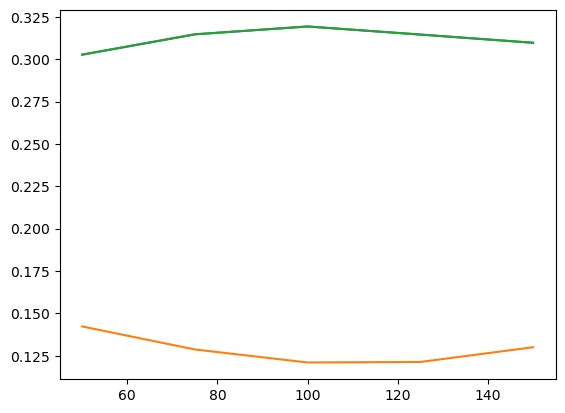

In [9]:
for i in range(3):
    plt.plot(coupleLength_arr, outputs_null[:,0,i])

In [6]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename = "Tricoupler_FiberTwoInput"

filename_root = filename
save_dir = working_dir+f"{filename_root}_scan_Wav_coupleLength"
filename = f"{filename}.ind"

wav_arr = np.linspace(1.45, 1.65, 11)
coupleLength_arr = np.linspace(0.5*308, 1.5*308, 31)

# Make scan save directory if it doesn't exist
os.makedirs(f"{save_dir}\\", exist_ok=True)

for i, wav in tqdm(enumerate(wav_arr), desc='Wavelength loop', position=0, leave=False):
    for coupleLength in tqdm(coupleLength_arr, desc=f"Coupling length loop (Wavelength: {wav} microns)", position=1, leave=False):
        # Read in circuit, set probe wavelength
        phase = 180
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("PhaseShift", phase)
        c.set_symbol("TricouplerCoupleLength", coupleLength)#*np.exp(-4))
        c.write(working_dir+filename)
        wav_str, phase_str, coupleLength_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p"), f"{coupleLength:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}",
                   "wait=0"] 
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)
    
        # Read in circuit, set probe wavelength
        phase = 0
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("PhaseShift", phase)
        c.set_symbol("TricouplerCoupleLength", coupleLength)#*np.exp(-4))
        c.write(working_dir+filename)
        wav_str, phase_str, coupleLength_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p"), f"{coupleLength:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}",
                   "wait=0"] 
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

np.save(f"{save_dir}/{filename_root}_Wav.npy", wav_arr)
np.save(f"{save_dir}/{filename_root}_CouplingLength.npy", coupleLength_arr)

Wavelength loop: 0it [00:00, ?it/s]
Coupling length loop (Wavelength: 1.45 microns):   0%|                                          | 0/31 [00:00<?, ?it/s]
Coupling length loop (Wavelength: 1.45 microns):   3%|█                              | 1/31 [02:46<1:23:11, 166.39s/it]
Coupling length loop (Wavelength: 1.45 microns):   6%|██                             | 2/31 [05:34<1:20:49, 167.21s/it]
Coupling length loop (Wavelength: 1.45 microns): 100%|██████████████████████████████| 31/31 [1:31:06<00:00, 184.71s/it]
Wavelength loop: 1it [1:31:06, 5466.20s/it]                                                                            
Coupling length loop (Wavelength: 1.47 microns):   0%|                                          | 0/31 [00:00<?, ?it/s]
Coupling length loop (Wavelength: 1.47 microns):   3%|█                              | 1/31 [02:46<1:23:10, 166.34s/it]
Coupling length loop (Wavelength: 1.47 microns):   6%|██                             | 2/31 [05:32<1:20:25, 166.40s/it]
Coup

### Cascaded tricoupler

In [60]:
np.linspace(250, 350, 5)

array([250., 275., 300., 325., 350.])

In [ ]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
wav, phase = 1.55, 180
# wav_str, phase_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p")
filename_root = f"Tricoupler_2Layer"
wav_str, phase_str = str(wav).replace('.', 'p'), str(phase).replace('.', 'p')
save_dir = working_dir+f"{filename_root}_wav{wav_str}_phase{phase_str}_scan_CoupleLength_DecoupleLength_CoupleLengthTwo"
filename = f"{filename_root}.ind"

coupleLength_arr = np.linspace(0.5*308, 1.5*308, 31)
decoupleLength_arr = np.linspace(0.5*308, 1.5*308, 31)
coupleLength2_arr = np.linspace(0.5*308, 1.5*308, 5)

# Make scan save directory if it doesn't exist
os.makedirs(f"{save_dir}\\", exist_ok=True)

for coupleLength in tqdm(coupleLength_arr, desc='Couple length loop', position=0, leave=False):
    for decoupleLength in tqdm(decoupleLength_arr, desc=f"Decouple length loop (Couple length: {coupleLength} microns)", position=1, leave=False): 
        for coupleLength2 in tqdm(coupleLength2_arr, desc=f"Couple length 2 loop (Couple length: {coupleLength} microns, Decouple length: {decoupleLength} microns)", position=1, leave=False): 
            # Read in circuit, set probe wavelength
            c = RSoftCircuit()
            c.read(working_dir+filename)
            c.set_symbol("free_space_wavelength", wav)
            c.set_symbol("PhaseShift", phase)
            c.set_symbol("TricouplerCoupleLength", coupleLength)
            c.set_symbol("TricouplerDecoupleLength", decoupleLength)
            c.set_symbol("TricouplerCoupleLength2", coupleLength2)
            c.write(working_dir+filename)
    
            couple_str = f"{coupleLength:0.3f}".replace(".", "p")
            decouple_str = f"{decoupleLength:0.3f}".replace(".", "p")
            couple2_str = f"{coupleLength2:0.3f}".replace(".", "p")
            command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_wav{wav_str}_phase{phase_str}_scan_CoupleLength{couple_str}_DecoupleLength{decouple_str}_CoupleLengthTwo{couple2_str}", "wait=0"]
            
            # Run the command
            result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

np.save(f"{save_dir}/{filename_root}_CoupleLength.npy", coupleLength_arr)
np.save(f"{save_dir}/{filename_root}_DecoupleLength.npy", decoupleLength_arr)
np.save(f"{save_dir}/{filename_root}_CoupleLengthTwo.npy", coupleLength2_arr)

Couple length loop:   0%|                                                                       | 0/31 [00:00<?, ?it/s]
Decouple length loop (Couple length: 154.0 microns):   0%|                                      | 0/31 [00:00<?, ?it/s]
Couple length 2 loop (Couple length: 154.0 microns, Decouple length: 154.0 microns):   0%|       | 0/5 [00:00<?, ?it/s]
Couple length 2 loop (Couple length: 154.0 microns, Decouple length: 154.0 microns):  20%|▏| 1/5 [00:09<00:36,  9.22s/i
Couple length 2 loop (Couple length: 154.0 microns, Decouple length: 154.0 microns):  40%|▍| 2/5 [00:19<00:28,  9.65s/i
Couple length 2 loop (Couple length: 154.0 microns, Decouple length: 154.0 microns):  60%|▌| 3/5 [00:29<00:19,  9.78s/i
Couple length 2 loop (Couple length: 154.0 microns, Decouple length: 154.0 microns):  80%|▊| 4/5 [00:37<00:09,  9.23s/i
Couple length 2 loop (Couple length: 154.0 microns, Decouple length: 154.0 microns): 100%|█| 5/5 [00:46<00:00,  9.25s/i
                                        

In [8]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename_root = "Tricoupler_2Layer"
CoupleLength = 209.44
DecoupleLength = 320.32
save_dir = working_dir+f"{filename_root}_CoupleLength{str(CoupleLength).replace('.', 'p')}_DecoupleLength{str(DecoupleLength).replace('.', 'p')}_scan_Wav_Phase"
filename = f"{filename_root}.ind"

wav_arr = np.linspace(1.48, 1.62, 51)
phase_arr = np.linspace(0, 360, 51)

# Make scan save directory if it doesn't exist
os.makedirs(f"{save_dir}\\", exist_ok=True)

for i, wav in tqdm(enumerate(wav_arr), desc='Wavelength loop', position=0, leave=False):
    for phase in tqdm(phase_arr, desc=f"Phase loop (Wavelength: {wav} microns)", position=1, leave=False): 
        # Read in circuit, set probe wavelength
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("PhaseShift", phase)
        c.set_symbol("TricouplerCoupleLength", CoupleLength)
        c.set_symbol("TricouplerDecoupleLength", DecoupleLength)
        c.write(working_dir+filename)

        wav_str = f"{wav:0.3f}".replace(".", "p")
        phase_str = f"{phase:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_CoupleLength{str(CoupleLength).replace('.', 'p')}_DecoupleLength{str(DecoupleLength).replace('.', 'p')}_scan_Wav{wav_str}_Phase{phase_str}", "wait=0"]
        
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

np.save(f"{save_dir}/{filename_root}_CoupleLength{str(CoupleLength).replace('.', 'p')}_DecoupleLength{str(DecoupleLength).replace('.', 'p')}_Wav.npy", wav_arr)
np.save(f"{save_dir}/{filename_root}_CoupleLength{str(CoupleLength).replace('.', 'p')}_DecoupleLength{str(DecoupleLength).replace('.', 'p')}_Phase.npy", phase_arr)

Wavelength loop: 0it [00:00, ?it/s]
Phase loop (Wavelength: 1.48 microns):   0%|                                                    | 0/51 [00:00<?, ?it/s]
                                                                                                                       Exception ignored in: <generator object tqdm.__iter__ at 0x0000022EF8584040>
Traceback (most recent call last):
  File "C:\Users\runner\anaconda3\envs\rsoft\Lib\site-packages\tqdm\std.py", line 1196, in __iter__
    self.close()
  File "C:\Users\runner\anaconda3\envs\rsoft\Lib\site-packages\tqdm\std.py", line 1306, in close
    if self.display(msg='', pos=pos) and not pos:
       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\runner\anaconda3\envs\rsoft\Lib\site-packages\tqdm\std.py", line 1495, in display
    self.sp(self.__str__() if msg is None else msg)
  File "C:\Users\runner\anaconda3\envs\rsoft\Lib\site-packages\tqdm\std.py", line 459, in print_status
    fp_write('\r' + s + (' ' * max(last_len[0] - len_s, 0)

KeyboardInterrupt: 

Plot all outputs

0.7880619 0.7274804
0.7802628 0.7321845
0.7737473 0.7322202
0.7666491 0.7282841
0.7591417 0.7199311
0.7515589 0.7082808
0.7440482 0.6922837
0.7367445 0.6719478
0.7296461 0.6481978
0.7226477 0.6210803
0.7157096 0.5907989


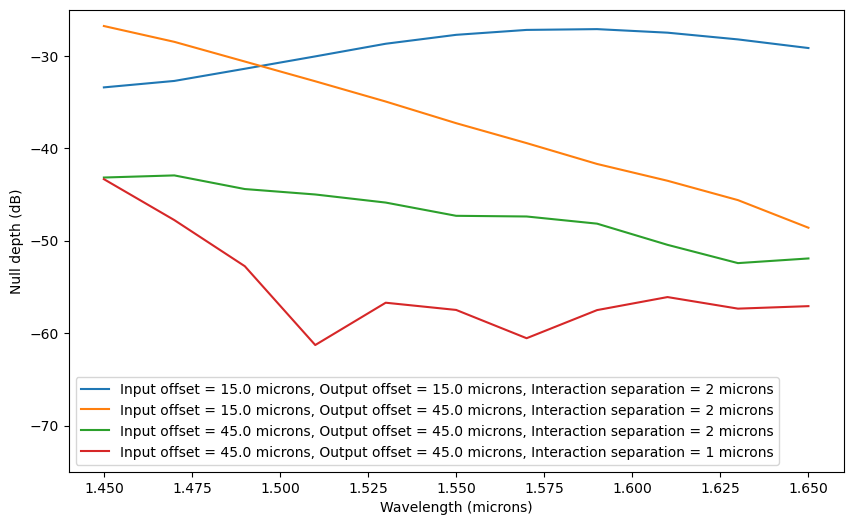

In [17]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename_root = "Tricoupler_FiberTwoInput"
save_dir = working_dir+f"{filename_root}_scan_Wav"
wavs = np.load(f"{save_dir}/{filename_root}_Wav.npy")

norm_dir = r"C:\\Users\\runner\\ActivePIC\\SbendWaveguide\\SbendWaveguide_scan_Wav\\"
norm_files = glob.glob(norm_dir+"*.mon")

output_A, output_B, output_C = [], [], []
for wav in wavs:
    row_phase, row_A, row_B, row_C = [], [], [], []
    wav_str = f"{wav:.3f}".replace('.', 'p')
    norm_filename = norm_dir+f"SbendWaveguide_scan_Wav{wav_str}.mon"
    norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
    norm = norm_mon[-1, 1]
    
    filename_base = os.path.basename(save_dir).split("_scan")[0]
    BendOffsetInput_0, BendOffsetOutput_0, sep_0 = 15., 15., 2
    offsetIn_str, offsetOut_str, sep_str = f"{BendOffsetInput_0:0.3f}".replace(".", "p"), f"{BendOffsetOutput_0:0.3f}".replace(".", "p"), f"{sep_0:0.3f}".replace(".", "p")
    filename = save_dir+f"\\{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}.mon"
    sim_0 = np.genfromtxt(filename, skip_header=5)
    filename = save_dir+f"\\{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}_CoupleSep{sep_str}_norm.mon"
    sim_0_norm = np.genfromtxt(filename, skip_header=5)

    BendOffsetInput_1, BendOffsetOutput_1, sep_1 = 15., 15.*3, 2
    offsetIn_str, offsetOut_str, sep_str = f"{BendOffsetInput_1:0.3f}".replace(".", "p"), f"{BendOffsetOutput_1:0.3f}".replace(".", "p"), f"{sep_1:0.3f}".replace(".", "p")
    filename = save_dir+f"/{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}.mon"
    sim_1 = np.genfromtxt(filename, skip_header=5)
    filename = save_dir+f"/{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}_CoupleSep{sep_str}_norm.mon"
    sim_1_norm = np.genfromtxt(filename, skip_header=5)

    BendOffsetInput_2, BendOffsetOutput_2, sep_2 = 15.*3, 15.*3, 2
    offsetIn_str, offsetOut_str, sep_str = f"{BendOffsetInput_2:0.3f}".replace(".", "p"), f"{BendOffsetOutput_2:0.3f}".replace(".", "p"), f"{sep_2:0.3f}".replace(".", "p")
    filename = save_dir+f"\\{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}.mon"
    sim_2 = np.genfromtxt(filename, skip_header=5)
    filename = save_dir+f"\\{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}_CoupleSep{sep_str}_norm.mon"
    sim_2_norm = np.genfromtxt(filename, skip_header=5)

    BendOffsetInput_3, BendOffsetOutput_3, sep_3 = 15.*3, 15.*3, 1
    offsetIn_str, offsetOut_str, sep_str = f"{BendOffsetInput_3:0.3f}".replace(".", "p"), f"{BendOffsetOutput_3:0.3f}".replace(".", "p"), f"{sep_3:0.3f}".replace(".", "p")
    filename = save_dir+f"\\{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}_CoupleSep{sep_str}.mon"
    sim_3 = np.genfromtxt(filename, skip_header=5)
    filename = save_dir+f"\\{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}_CoupleSep{sep_str}_norm.mon"
    sim_3_norm = np.genfromtxt(filename, skip_header=5)

    print(norm, sim_3_norm[-1,2])
    
    # output_A.append([sim_0[-1,1]/norm, sim_1[-1,1]/norm, sim_2[-1,1]/norm, sim_3[-1,1]/norm])
    output_B.append([sim_0[-1,2]/sim_0_norm[-1,2], sim_1[-1,2]/sim_1_norm[-1,2], sim_2[-1,2]/sim_2_norm[-1,2], sim_3[-1,2]/sim_3_norm[-1,2]])
    # output_B.append([sim_0[-1,3]/norm, sim_1[-1,3]/norm, sim_2[-1,3]/norm, sim_3[-1,3]/norm])
    # output_C.append([sim_0[-1,3]/norm, sim_1[-1,3]/norm, sim_2[-1,3]/norm, sim_3[-1,3]/norm])       
# output_A, output_B, output_C = np.array(output_A), np.array(output_B), np.array(output_C)
output_B = np.array(output_B)

plt.figure(figsize=(10,6))
plt.plot(wavs, 10*np.log10(output_B[:, 0]), label=f'Input offset = {BendOffsetInput_0} microns, Output offset = {BendOffsetOutput_0} microns, Interaction separation = 2 microns')
plt.plot(wavs, 10*np.log10(output_B[:, 1]), label=f'Input offset = {BendOffsetInput_1} microns, Output offset = {BendOffsetOutput_1} microns, Interaction separation = 2 microns')
plt.plot(wavs, 10*np.log10(output_B[:, 2]), label=f'Input offset = {BendOffsetInput_2} microns, Output offset = {BendOffsetOutput_2} microns, Interaction separation = 2 microns')
plt.plot(wavs, 10*np.log10(output_B[:, 3]), label=f'Input offset = {BendOffsetInput_3} microns, Output offset = {BendOffsetOutput_3} microns, Interaction separation = {sep_3} microns')
plt.ylim(-75, -25)
plt.xlabel('Wavelength (microns)')
plt.ylabel('Null depth (dB)')
plt.legend()
plt.show()

In [13]:
root_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
norm_dir = r"C:\\Users\\runner\\ActivePIC\\SbendWaveguide\\SbendWaveguide_scan_Wav\\"
norm_files = glob.glob(norm_dir+"*.mon")
root_left = 'Tricoupler_FiberOneInput_Left_scan_Wav'
root_right = 'Tricoupler_FiberOneInput_Right_scan_Wav'
root_center = 'Tricoupler_FiberOneInput_Center_scan_Wav'

wavs, outputs_left, outputs_center, outputs_right = [], [], [], []
lengths = np.load(f"{save_dir}/{filename_root}_CouplingLength.npy")
for norm_file in norm_files:
    wav_str = norm_file.split('.mon')[0].split('_Wav')[-1]
    wav = float(wav_str.replace('p', '.'))
    wavs.append(wav)
    norm_mon = np.genfromtxt(norm_file, delimiter='', skip_header=5)
    norm = norm_mon[-1, 1]
    
    filename_left = root_dir+f"{root_left}\\Tricoupler_FiberOneInput_Left_scan_Wav{wav_str}.mon"
    sim = np.genfromtxt(filename_left, skip_header=5)
    outputs_left.append([sim[-1,1]/norm, sim[-1,2]/norm, sim[-1,3]/norm])   

    filename_right = root_dir+f"{root_right}\\Tricoupler_FiberOneInput_Right_scan_Wav{wav_str}.mon"
    sim = np.genfromtxt(filename_right, skip_header=5)
    outputs_right.append([sim[-1,1]/norm, sim[-1,2]/norm, sim[-1,3]/norm]) 

    filename_center = root_dir+f"{root_center}\\Tricoupler_FiberOneInput_Center_scan_Wav{wav_str}.mon"
    sim = np.genfromtxt(filename_center, skip_header=5)
    outputs_center.append([sim[-1,1]/norm, sim[-1,2]/norm, sim[-1,3]/norm]) 
wavs = np.array(wavs)
inputs = [np.array(outputs_left).T, np.array(outputs_center).T, np.array(outputs_right).T]

wav_range = [1450, 1650]

fig, ax = plt.subplots(1, 3, figsize=(14,6), sharey=True)
plt.subplots_adjust(wspace=0)
for i_ind, outputs in enumerate(inputs):
    for o_ind in range(len(outputs)):
        ax[i_ind].plot(wavs*1000, outputs[o_ind], label=f'Output {chr(ord("A") + o_ind)}', color=f'C{o_ind}')    
    ax[i_ind].set_xlim(wav_range[0], wav_range[1])
    ax[i_ind].set_ylim(0, 1)
    ax[i_ind].set_title(f'Input {chr(ord("A") + i_ind)}')
for i in range(2):
    ticks = ax[i].get_xticks()
    labels = [int(t) if t != 1650 else '' for t in ticks]  # blank for 1650
    ax[i].set_xticklabels(labels)
ax[1].set_xlabel('Wavelength (nm)')
ax[0].set_ylabel('Throughput')
plt.legend()
fig.suptitle(f'Coupling length: {length} microns')
plt.show()

np.save(f"{root_dir}\\{root_left}\\{root_left}_wavs", wavs)
np.save(f"{root_dir}\\{root_left}\\{root_left}_outputs", np.array(outputs_left).T)
np.save(f"{root_dir}\\{root_center}\\{root_center}_wavs", wavs)
np.save(f"{root_dir}\\{root_center}\\{root_center}_outputs", np.array(outputs_center).T)
np.save(f"{root_dir}\\{root_right}\\{root_right}_wavs", wavs)
np.save(f"{root_dir}\\{root_right}\\{root_right}_outputs", np.array(outputs_right).T)

FileNotFoundError: C:\Users\runner\ActivePIC\Tricoupler\Tricoupler_FiberOneInput_Left_scan_Wav\Tricoupler_FiberOneInput_Left_scan_Wav1p450.mon not found.

In [38]:
inputs_left

[[1.0551933738663288, 0.0, 0.0],
 [1.0551422355749611, 0.0, 0.0],
 [1.0550672792106397, 0.0, 0.0],
 [1.0550001048609978, 0.0, 0.0],
 [1.0549635680747325, 0.0, 0.0],
 [1.0618252193668392, 0.0, 0.0],
 [1.061764405883706, 0.0, 0.0],
 [1.0617541022193115, 0.0, 0.0],
 [1.0618344244576097, 0.0, 0.0],
 [1.0619852820643247, 0.0, 0.0],
 [1.0621973858483242, 0.0, 0.0],
 [1.0624571065899528, 0.0, 0.0],
 [1.0627413980765852, 0.0, 0.0],
 [1.0631126214776103, 0.0, 0.0],
 [1.063334497648324, 0.0, 0.0],
 [1.0634974756907303, 0.0, 0.0],
 [1.0635931045012803, 0.0, 0.0],
 [1.0636130354757964, 0.0, 0.0],
 [1.0635779468779176, 0.0, 0.0],
 [1.063493917496119, 0.0, 0.0],
 [1.0633843736109683, 0.0, 0.0],
 [1.0632553807480767, 0.0, 0.0],
 [1.063134786460632, 0.0, 0.0],
 [1.0629917376771651, 0.0, 0.0],
 [1.0629142590725282, 0.0, 0.0],
 [1.0628758472711106, 0.0, 0.0],
 [1.0628650454105837, 0.0, 0.0],
 [1.0628959334741455, 0.0, 0.0],
 [1.062944215773205, 0.0, 0.0],
 [1.0630453794943084, 0.0, 0.0],
 [1.06315896790

C:\Users\runner\AppData\Local\Temp\ipykernel_14640\481491212.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(labels)
C:\Users\runner\AppData\Local\Temp\ipykernel_14640\481491212.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(labels)


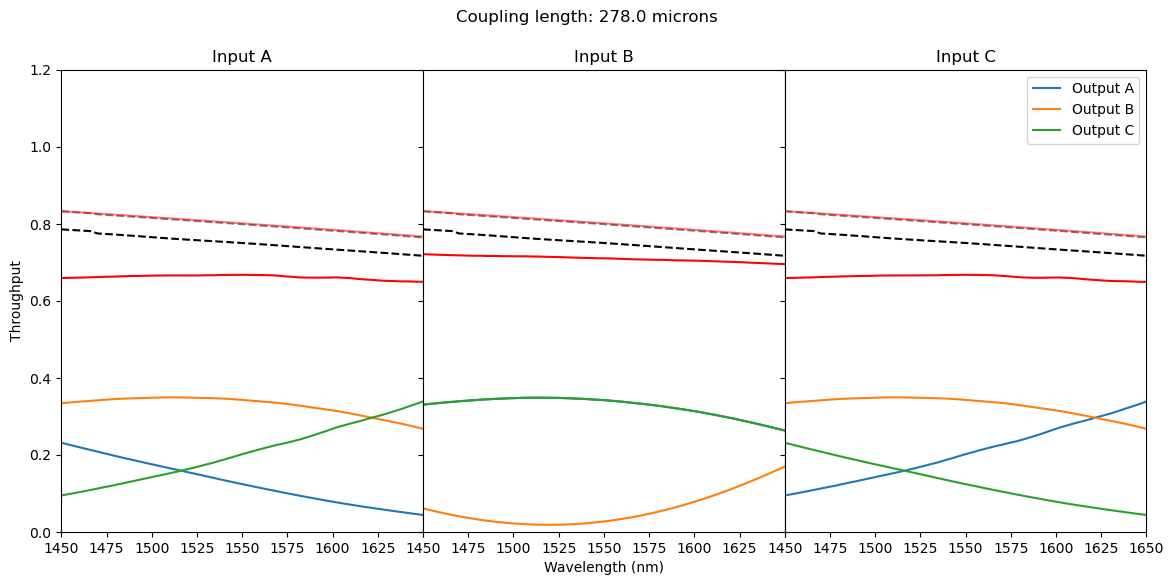

C:\Users\runner\AppData\Local\Temp\ipykernel_14640\481491212.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(labels)
C:\Users\runner\AppData\Local\Temp\ipykernel_14640\481491212.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(labels)


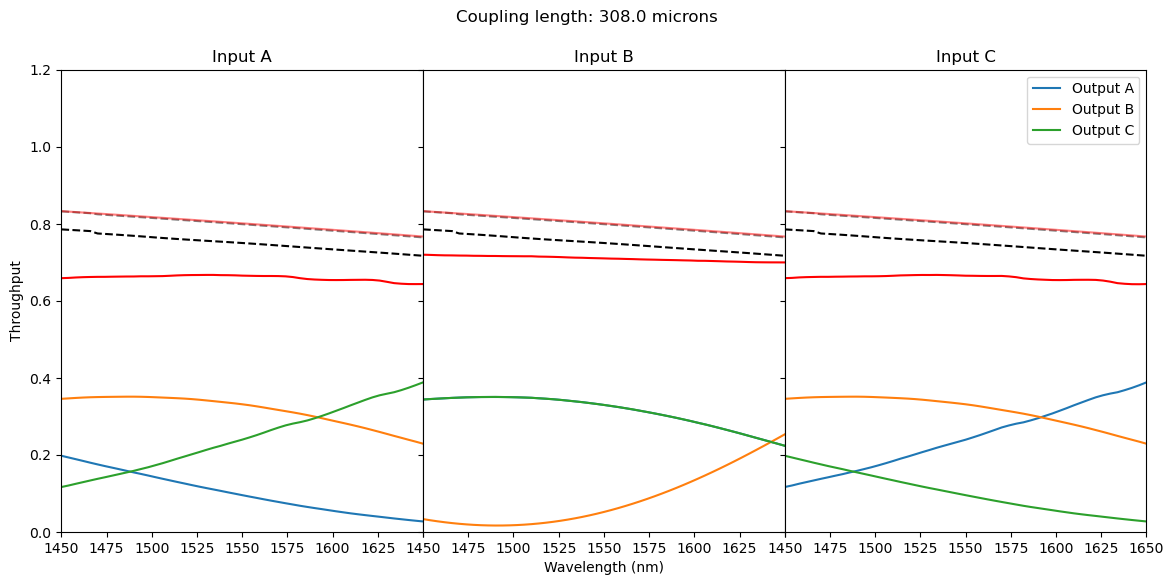

C:\Users\runner\AppData\Local\Temp\ipykernel_14640\481491212.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(labels)
C:\Users\runner\AppData\Local\Temp\ipykernel_14640\481491212.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(labels)


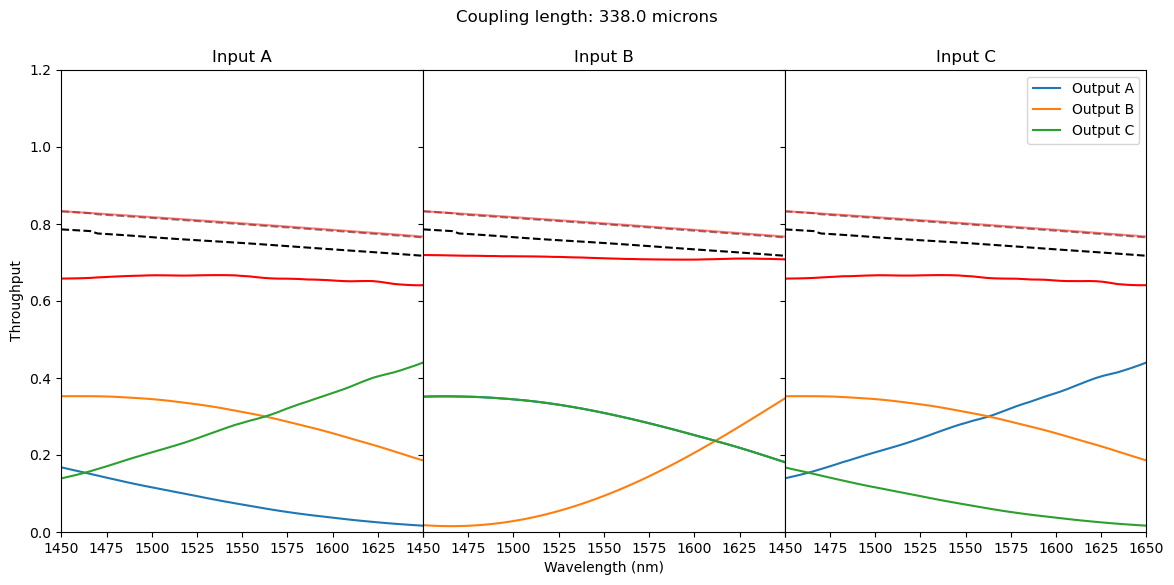

In [54]:
root_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
norm_dir = r"C:\\Users\\runner\\ActivePIC\\SbendWaveguide\\SbendWaveguide_scan_Wav\\"
norm_files = glob.glob(norm_dir+"*.mon")
sbend_str = '_RaisedSineSbend'
root_left = f'Tricoupler_FiberOneInput_Left{sbend_str}_scan_Wav_CouplingLength'
root_right = f'Tricoupler_FiberOneInput_Right{sbend_str}_scan_Wav_CouplingLength'
root_center = f'Tricoupler_FiberOneInput_Center{sbend_str}_scan_Wav_CouplingLength'

for length in length_arr:
    wavs, outputs_left, outputs_center, outputs_right = [], [], [], []
    inputs_left, inputs_center, inputs_right = [], [], []
    norms, norms_in= [], []
    length_str = f"{length:0.3f}".replace(".", "p") 
    for norm_file in norm_files:
        wav_str = norm_file.split('.mon')[0].split('_Wav')[-1]
        wav = float(wav_str.replace('p', '.'))
        wavs.append(wav)
        norm_mon = np.genfromtxt(norm_file, delimiter='', skip_header=5)
        norm, norm_in = norm_mon[-1, 1], norm_mon[0, 1]
        norms.append(norm)
        norms_in.append(norm_in)
        # print(norm)
        
        filename_left = root_dir+f"{root_left}\\Tricoupler_FiberOneInput_Left{sbend_str}_scan_Wav{wav_str}_CouplingLength{length_str}.mon"
        sim = np.genfromtxt(filename_left, skip_header=5)
        outputs_left.append([sim[-1,1], sim[-1,2], sim[-1,3]])   
        inputs_left.append([sim[1,1], sim[1,2], sim[1,3]])   
    
        filename_right = root_dir+f"{root_right}\\Tricoupler_FiberOneInput_Right{sbend_str}_scan_Wav{wav_str}_CouplingLength{length_str}.mon"
        sim = np.genfromtxt(filename_right, skip_header=5)
        outputs_right.append([sim[-1,1], sim[-1,2], sim[-1,3]])
        inputs_right.append([sim[1,1], sim[1,2], sim[1,3]])
    
        filename_center = root_dir+f"{root_center}\\Tricoupler_FiberOneInput_Center{sbend_str}_scan_Wav{wav_str}_CouplingLength{length_str}.mon"
        sim = np.genfromtxt(filename_center, skip_header=5)
        outputs_center.append([sim[-1,1], sim[-1,2], sim[-1,3]])
        inputs_center.append([sim[1,1], sim[1,2], sim[1,3]])
    wavs = np.array(wavs)
    inputs = [np.array(outputs_left).T, np.array(outputs_center).T, np.array(outputs_right).T]
    inputs_in = [np.array(inputs_left).T, np.array(inputs_center).T, np.array(inputs_right).T]
    
    wav_range = [1450, 1650]

    fig, ax = plt.subplots(1, 3, figsize=(14,6), sharey=True)
    plt.subplots_adjust(wspace=0)
    for i_ind, outputs in enumerate(inputs):
        for o_ind in range(len(outputs)):
            ax[i_ind].plot(wavs*1000, outputs[o_ind], label=f'Output {chr(ord("A") + o_ind)}', color=f'C{o_ind}')    
        ax[i_ind].plot(wavs*1000, norms, color='k', linestyle='dashed')
        ax[i_ind].plot(wavs*1000, norms_in, color='k', linestyle='dashed', alpha=0.5)
        ax[i_ind].plot(wavs*1000, np.sum(outputs, axis=0), color='r')
        ax[i_ind].plot(wavs*1000, np.sum(inputs_in[i_ind], axis=0), color='r', alpha=0.5)
        
        ax[i_ind].set_xlim(wav_range[0], wav_range[1])
        ax[i_ind].set_ylim(0, 1.2)
        ax[i_ind].set_title(f'Input {chr(ord("A") + i_ind)}')
    for i in range(2):
        ticks = ax[i].get_xticks()
        labels = [int(t) if t != 1650 else '' for t in ticks]  # blank for 1650
        ax[i].set_xticklabels(labels)
    ax[1].set_xlabel('Wavelength (nm)')
    ax[0].set_ylabel('Throughput')
    plt.legend()
    fig.suptitle(f'Coupling length: {length} microns')
    plt.show()
    
    np.save(f"{root_dir}\\{root_left}\\{root_left}{length_str}_wavs", wavs)
    np.save(f"{root_dir}\\{root_left}\\{root_left}{length_str}_outputs", np.array(outputs_left).T)
    np.save(f"{root_dir}\\{root_center}\\{root_center}{length_str}_wavs", wavs)
    np.save(f"{root_dir}\\{root_center}\\{root_center}{length_str}_outputs", np.array(outputs_center).T)
    np.save(f"{root_dir}\\{root_right}\\{root_right}{length_str}_wavs", wavs)
    np.save(f"{root_dir}\\{root_right}\\{root_right}{length_str}_outputs", np.array(outputs_right).T)

In [23]:
outputs.sum(axis=0), norm

array([0.57309549, 0.5776516 , 0.58181168, 0.58623118, 0.59039212,
       0.59812823, 0.6016518 , 0.60404405, 0.60674465, 0.60987777,
       0.61417229, 0.61832735, 0.62344167, 0.62892394, 0.63371501,
       0.63808473, 0.64252288, 0.64634733, 0.64969457, 0.65202992,
       0.65418513, 0.65634623, 0.65908197, 0.66266392, 0.66717826,
       0.67169611, 0.6762355 , 0.68036486, 0.68461002, 0.68737614,
       0.68923818, 0.69089179, 0.69279737, 0.69590343, 0.69983204,
       0.70466862, 0.70925221, 0.71373491, 0.71687833, 0.71939197,
       0.71979933, 0.72003364, 0.72102627, 0.72320245, 0.7272871 ,
       0.73308204, 0.73783988, 0.74106229, 0.74248618, 0.74235592,
       0.74237812])

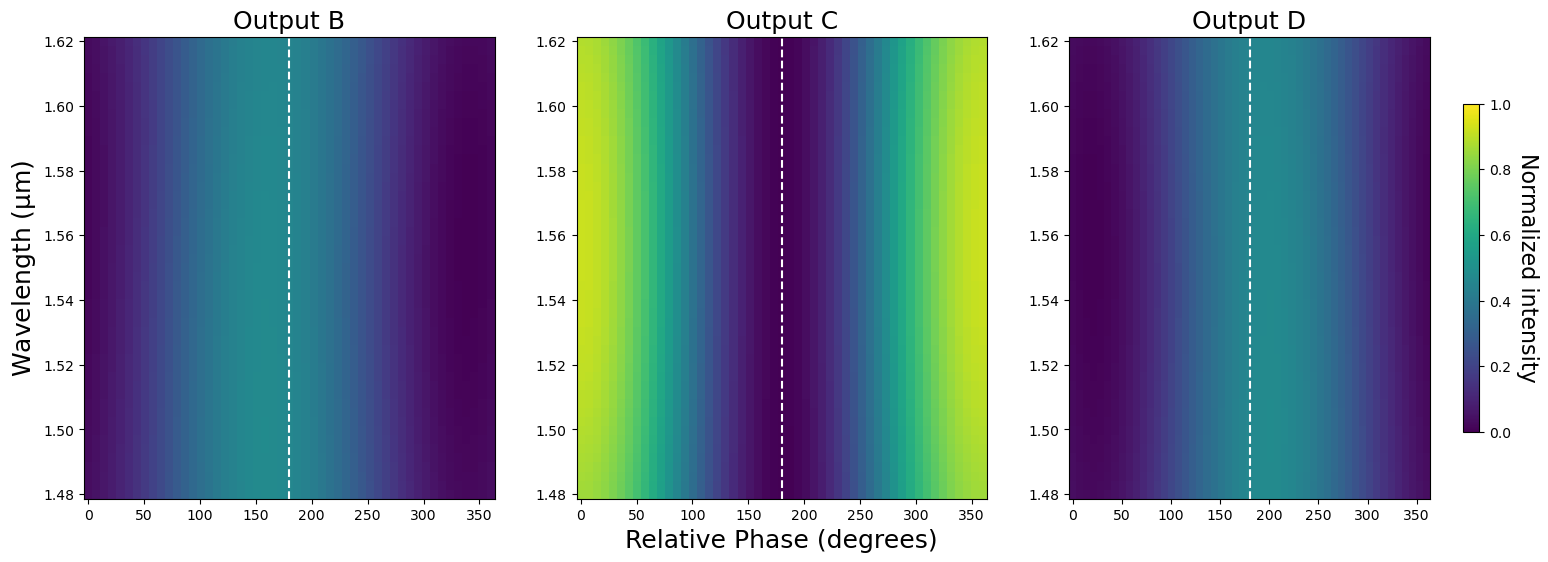

In [87]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\Tricoupler\\"

filename_root = "Tricoupler"
save_dir = working_dir+f"{filename_root}_scan_Wav_Phase"
phases = np.load(f"{save_dir}/{filename_root}_Phase.npy")
wavs = np.load(f"{save_dir}/{filename_root}_Wav.npy")

# filename_root = "Tricoupler_2Layer"
# CoupleLength, DecoupleLength = 209.44, 320.32
# save_dir = working_dir+f"{filename_root}_CoupleLength{str(CoupleLength).replace('.', 'p')}_DecoupleLength{str(DecoupleLength).replace('.', 'p')}_scan_Wav_Phase"
# phases = np.load(f"{save_dir}/{filename_root}_CoupleLength{str(CoupleLength).replace('.', 'p')}_DecoupleLength{str(DecoupleLength).replace('.', 'p')}_Phase.npy")
# wavs = np.load(f"{save_dir}/{filename_root}_CoupleLength{str(CoupleLength).replace('.', 'p')}_DecoupleLength{str(DecoupleLength).replace('.', 'p')}_Wav.npy")

norm_dir = r"C:\\Users\\runner\\ActivePIC\\StraightWaveguide\\StraightWaveguide_scan_Wav\\"

output_A, output_B, output_C = [], [], []
for wav in wavs:
    row_phase, row_A, row_B, row_C = [], [], [], []
    wav_str = f"{wav:.3f}".replace('.', 'p')
    norm_filename = norm_dir+f"StraightWaveguide_scan_Wav{wav_str}.mon"
    norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
    norm = norm_mon[-1, 1]
    for phase in phases:
        phase_str = f"{phase:.3f}".replace('.', 'p')
        filename_base = os.path.basename(save_dir).split("_scan")[0]
        filename = save_dir+f"/{filename_base}_scan_Wav{wav_str}_Phase{phase_str}.mon"
        sim = np.genfromtxt(filename, skip_header=5)
        row_A.append(sim[-1,1]/norm)
        row_B.append(sim[-1,2]/norm)
        row_C.append(sim[-1,3]/norm)        
    output_A.append(row_A)
    output_B.append(row_B)
    output_C.append(row_C)
output_A, output_B, output_C = np.array(output_A), np.array(output_B), np.array(output_C)
        
vmin, vmax = 0, 1
fig, ax = plt.subplots(1, 3, figsize=(18,6))
im = ax[0].pcolormesh(phases, wavs, output_A, vmin=vmin, vmax=vmax)
im = ax[1].pcolormesh(phases, wavs, output_B, vmin=vmin, vmax=vmax)
im = ax[2].pcolormesh(phases, wavs, output_C, vmin=vmin, vmax=vmax)
for i in range(3):
    # ax[i].axvline(0, linestyle='dashed', color='white')
    ax[i].axvline(180, linestyle='dashed', color='white')
ax[0].set_title('Output B', fontsize=18)
ax[1].set_title('Output C', fontsize=18)
ax[2].set_title('Output D', fontsize=18)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Normalized intensity', rotation=270, labelpad=20, fontsize=16)
ax[1].set_xlabel(f"Relative Phase (degrees)", fontsize=18)
ax[0].set_ylabel("Wavelength ($\mathrm{\mu}$m)", fontsize=18)
plt.savefig('C:\\Users\\runner\\ActivePIC\\SoL_figs\\Tricoupler_outputs.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [90]:
throughput = 10**(exoplanet_original/10)
np.min(throughput), np.max(throughput), wavs

(0.8554024449532575,
 0.9192235826467826,
 array([1.48  , 1.4828, 1.4856, 1.4884, 1.4912, 1.494 , 1.4968, 1.4996,
        1.5024, 1.5052, 1.508 , 1.5108, 1.5136, 1.5164, 1.5192, 1.522 ,
        1.5248, 1.5276, 1.5304, 1.5332, 1.536 , 1.5388, 1.5416, 1.5444,
        1.5472, 1.55  , 1.5528, 1.5556, 1.5584, 1.5612, 1.564 , 1.5668,
        1.5696, 1.5724, 1.5752, 1.578 , 1.5808, 1.5836, 1.5864, 1.5892,
        1.592 , 1.5948, 1.5976, 1.6004, 1.6032, 1.606 , 1.6088, 1.6116,
        1.6144, 1.6172, 1.62  ]))

Plot null depth

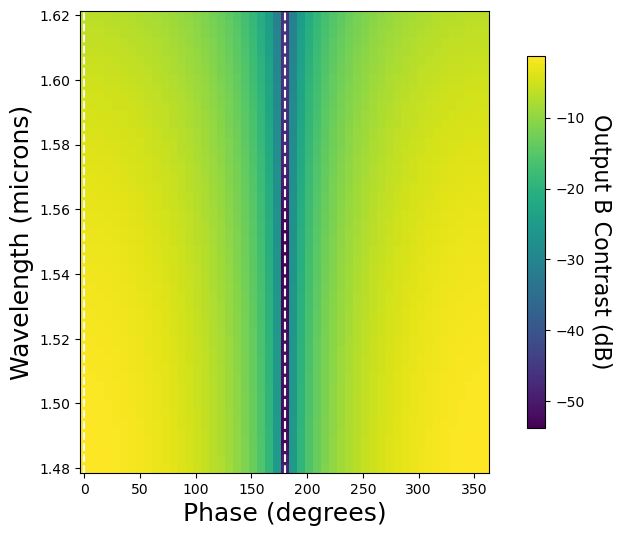

In [64]:
contrast = 10*np.log10(output_B)

fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(phases, wavs, contrast)
plt.axvline(0, linestyle='dashed', color='white')
plt.axvline(180, linestyle='dashed', color='white')
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Output B Contrast (dB)', rotation=270, labelpad=20, fontsize=16)
plt.xlabel(f"Phase (degrees)", fontsize=18)
plt.ylabel(f"Wavelength (microns)", fontsize=18)
plt.show()

In [65]:
ind = np.argmin(output_B)
row_min, col_min = np.unravel_index(ind, np.shape(output_B))
ind = np.argmax(output_B)
row_max, col_max = np.unravel_index(ind, np.shape(output_B))
print(f'Null depth: {10*np.log10(np.min(output_B)):0.2f} dB at wavelength = {wavs[row_min]} microns, phase shift = {phases[col_min]}')
print(f'Exoplanet throughput: {np.max(output_B)*100:0.2f}% at wavelength = {wavs[row_max]} microns, phase shift = {phases[col_max]}')

Null depth: -53.78 dB at wavelength = 1.5472000000000001 microns, phase shift = 180.0
Exoplanet throughput: 75.11% at wavelength = 1.48 microns, phase shift = 0.0


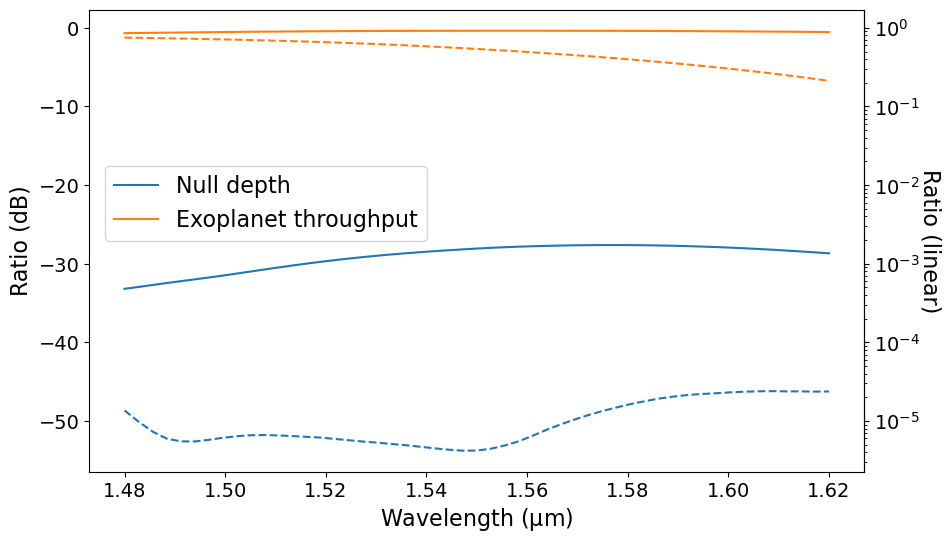

In [83]:
def db_to_linear(db):
    return 10 ** (db / 10)

def linear_to_db(lin):
    return 10 * np.log10(lin)

fig, ax = plt.subplots(figsize=(10,6))
ax.plot(wavs_original, null_original, color='C0', label='Null depth')
ax.plot(wavs_original, exoplanet_original, color='C1', label='Exoplanet throughput')
ax.plot(wavs_2Layer, null_2Layer, color='C0', linestyle='dashed')
ax.plot(wavs_2Layer, exoplanet_2Layer, color='C1', linestyle='dashed')

# Secondary axis
ax_lin = ax.secondary_yaxis(
    'right',
    functions=(db_to_linear, linear_to_db)
)
ax_lin.set_ylabel("Ratio (linear)", fontsize=16, rotation=270, labelpad=15)
ax_lin.set_yscale('log')

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
ax_lin.tick_params(axis='y', labelsize=14)
plt.xlabel('Wavelength ($\mathrm{\mu}$m)', fontsize=16)
plt.ylabel('Ratio (dB)', fontsize=16)
plt.legend(fontsize=16, loc=(0.02, 0.5))
plt.savefig('C:\\Users\\runner\\ActivePIC\\SoL_figs\\Tricoupler_2Layer_nullChromaticity.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [67]:
null_2Layer = np.copy(contrast[:, np.argwhere(phases==180)].flatten())
exoplanet_2Layer = np.copy(contrast[:, np.argwhere(phases==0)].flatten())
wavs_2Layer = np.copy(wavs)

Plot throughput

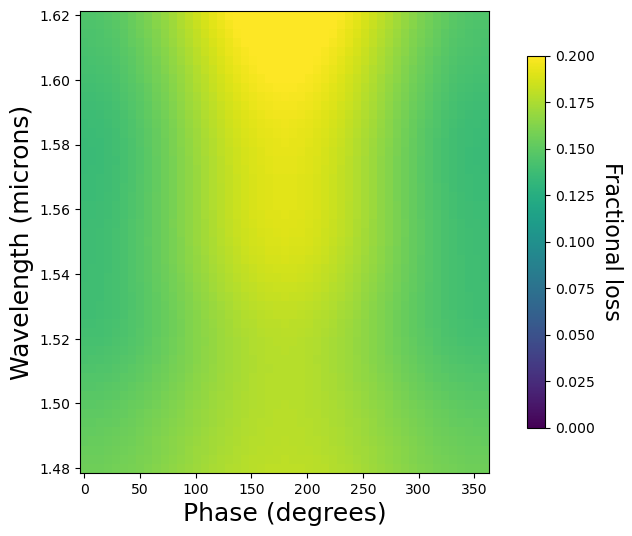

In [7]:
vmin, vmax = 0, 0.2
fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(phases, wavs, 1 - (output_A+output_B+output_C), vmin=vmin, vmax=vmax)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Fractional loss', rotation=270, labelpad=20, fontsize=16)
plt.xlabel(f"Phase (degrees)", fontsize=18)
plt.ylabel(f"Wavelength (microns)", fontsize=18)
plt.show()

In [8]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
wav, phase = 1.55, 180
wav_str, phase_str = str(wav).replace('.', 'p'), str(phase).replace('.', 'p')
filename_root = f"Tricoupler_2Layer_wav{wav_str}_phase{phase_str}"
save_dir = working_dir+f"{filename_root}_scan_CoupleLength_DecoupleLength"
norm_dir = r"C:\\Users\\runner\\ActivePIC\\StraightWaveguide\\StraightWaveguide_scan_Wav\\"

coupleLengths = np.load(f"{save_dir}/{filename_root}_CoupleLength.npy")
decoupleLengths = np.load(f"{save_dir}/{filename_root}_DecoupleLength.npy")
coupleLength2 = 308
coupleLength2_str = f"{coupleLength2:.3f}".replace('.', 'p')

output_A, output_B, output_C = [], [], []
for coupleLength in coupleLengths:
    row_phase, row_A, row_B, row_C = [], [], [], []
    coupleLength_str = f"{coupleLength:.3f}".replace('.', 'p')
    norm_filename = norm_dir+f"StraightWaveguide_scan_Wav{f'{wav:.3f}'.replace('.', 'p')}.mon"
    norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
    norm = norm_mon[-1, 1]
    for decoupleLength in decoupleLengths:
        decoupleLength_str = f"{decoupleLength:.3f}".replace('.', 'p')
        filename = save_dir+f"\\{filename_root}_scan_CoupleLength{coupleLength_str}_DecoupleLength{decoupleLength_str}_CoupleLength2{coupleLength_str}.mon"
        sim = np.genfromtxt(filename, skip_header=5)
        row_A.append(sim[-1,1]/norm)
        row_B.append(sim[-1,2]/norm)
        row_C.append(sim[-1,3]/norm)        
    output_A.append(row_A)
    output_B.append(row_B)
    output_C.append(row_C)
output_A, output_B, output_C = np.array(output_A), np.array(output_B), np.array(output_C)
        
vmin, vmax = 0, 1
fig, ax = plt.subplots(1, 3, figsize=(18,6))
im = ax[0].pcolormesh(decoupleLengths, coupleLengths, output_A, vmin=vmin, vmax=vmax)
im = ax[1].pcolormesh(decoupleLengths, coupleLengths, output_B, vmin=vmin, vmax=vmax)
im = ax[2].pcolormesh(decoupleLengths, coupleLengths, output_C, vmin=vmin, vmax=vmax)
ax[0].set_title('Output A', fontsize=18)
ax[1].set_title('Output B', fontsize=18)
ax[2].set_title('Output C', fontsize=18)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Normalized intensity', rotation=270, labelpad=20, fontsize=16)
ax[1].set_xlabel(f"Decouple Length (microns)", fontsize=18)
ax[0].set_ylabel(f"Couple Length (microns)", fontsize=18)
plt.show()

contrast = 10*np.log10(output_B/(output_A + output_C))

fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(decoupleLengths, coupleLengths, contrast)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Null depth (dB)', rotation=270, labelpad=20, fontsize=16)
ax.set_xlabel("Decouple Length ($\mathrm{\mu}$m)", fontsize=18)
ax.set_ylabel("Couple Length ($\mathrm{\mu}$m)", fontsize=18)
plt.show()

FileNotFoundError: C:\\Users\\runner\\ActivePIC\\Tricoupler\\Tricoupler_2Layer_wav1p55_phase180_scan_CoupleLength_DecoupleLength\Tricoupler_2Layer_wav1p55_phase180_scan_CoupleLength154p000_DecoupleLength154p000_CoupleLength2154p000.mon not found.

# Optimize multilayer tricoupler specs

In [7]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename_root = "Tricoupler_2Layer"
wav, phase = 1.55, 0
wav_str, phase_str = str(wav).replace('.', 'p'), str(phase).replace('.', 'p')
save_dir = working_dir+f"{filename_root}_wav{wav_str}_phase{phase_str}_scan_CoupleLength_DecoupleLength"
filename = f"{filename_root}.ind"

coupleLength_arr = np.linspace(0.5*308, 1.5*308, 51)
decoupleLength_arr = np.linspace(0.5*308, 1.5*308, 51)

# Make scan save directory if it doesn't exist
os.makedirs(f"{save_dir}\\", exist_ok=True)

for coupleLength in tqdm(coupleLength_arr, desc='Couple length loop', position=0, leave=False):
    for decoupleLength in tqdm(decoupleLength_arr, desc=f"Decouple length loop (Couple length: {coupleLength} microns)", position=1, leave=False): 
        # Read in circuit, set probe wavelength
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("PhaseShift", phase)
        c.set_symbol("TricouplerCoupleLength", coupleLength)
        c.set_symbol("TricouplerDecoupleLength", decoupleLength)
        c.write(working_dir+filename)

        couple_str = f"{coupleLength:0.3f}".replace(".", "p")
        decouple_str = f"{decoupleLength:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_wav{wav_str}_phase{phase_str}_scan_CoupleLength{couple_str}_DecoupleLength{decouple_str}", "wait=0"]
        
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

np.save(f"{save_dir}/{filename_root}_CoupleLength.npy", coupleLength_arr)
np.save(f"{save_dir}/{filename_root}_DecoupleLength.npy", decoupleLength_arr)

Couple length loop:   0%|                                                         | 0/51 [00:00<?, ?it/s]
Decouple length loop (Couple length: 154.0 microns):   0%|                        | 0/51 [00:00<?, ?it/s]
Decouple length loop (Couple length: 154.0 microns):   2%|▎               | 1/51 [00:09<08:06,  9.74s/it]
Decouple length loop (Couple length: 154.0 microns):   4%|▋               | 2/51 [00:18<07:31,  9.22s/it]
Decouple length loop (Couple length: 154.0 microns):   6%|▉               | 3/51 [00:33<09:32, 11.92s/it]
Decouple length loop (Couple length: 154.0 microns):   8%|█▎              | 4/51 [00:48<10:14, 13.08s/it]
Decouple length loop (Couple length: 154.0 microns):  10%|█▌              | 5/51 [01:03<10:27, 13.63s/it]
Decouple length loop (Couple length: 154.0 microns):  12%|█▉              | 6/51 [01:17<10:28, 13.97s/it]
Decouple length loop (Couple length: 154.0 microns):  14%|██▏             | 7/51 [01:33<10:35, 14.43s/it]
Decouple length loop (Couple length: 154.0 mic

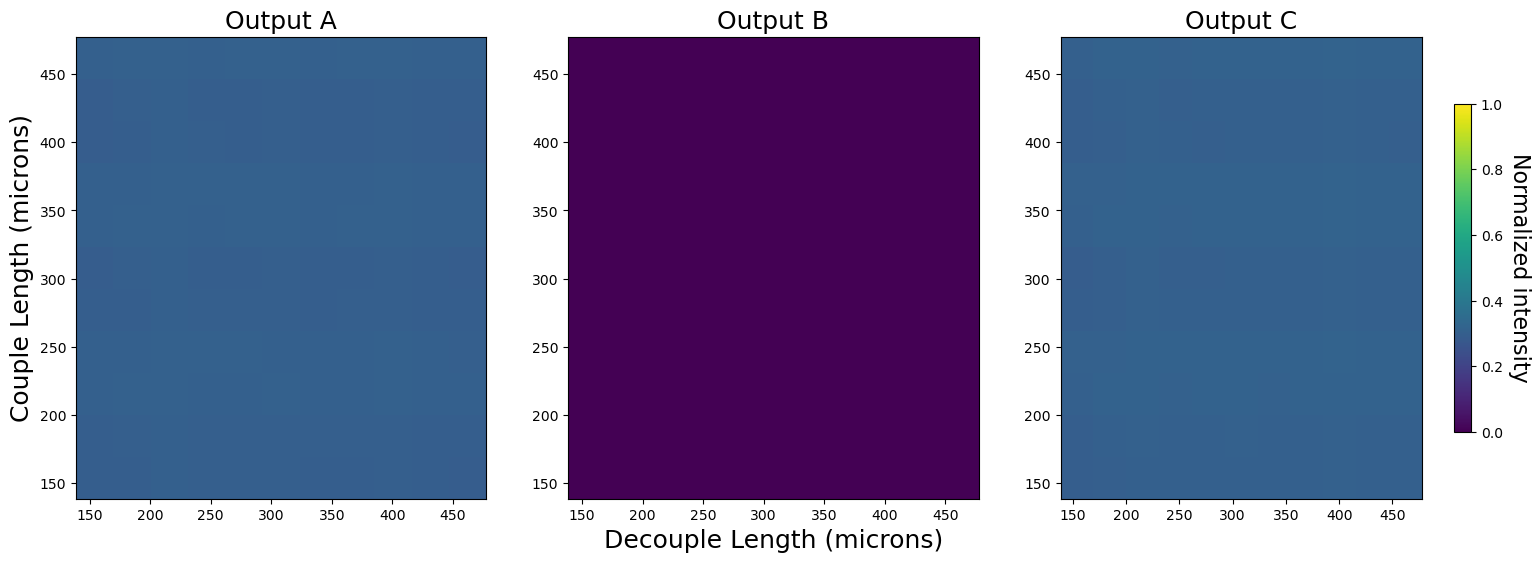

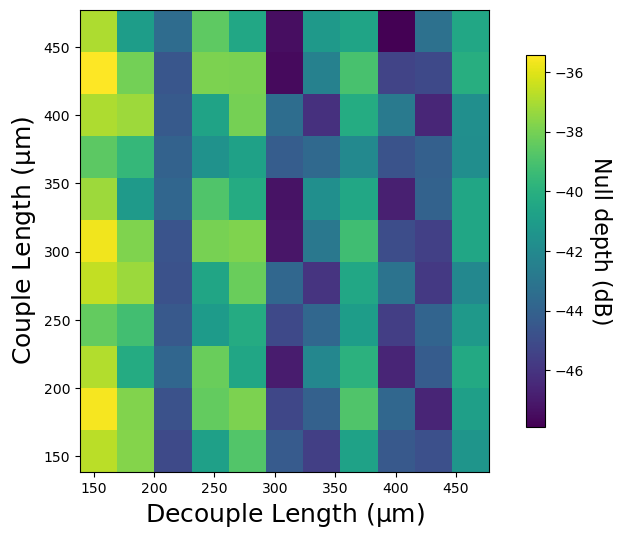

In [58]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
wav, phase = 1.55, 180
wav_str, phase_str = str(wav).replace('.', 'p'), str(phase).replace('.', 'p')
filename_root = f"Tricoupler_2Layer_wav{wav_str}_phase{phase_str}"
save_dir = working_dir+f"{filename_root}_scan_CoupleLength_DecoupleLength_CoupleLength2"

coupleLengths = np.load(f"{save_dir}/Tricoupler_2Layer_CoupleLength.npy")
decoupleLengths = np.load(f"{save_dir}/Tricoupler_2Layer_DecoupleLength.npy")
coupleLengths2 = np.load(f"{save_dir}/Tricoupler_2Layer_CoupleLength2.npy")

outputs_A, outputs_B, outputs_C = [], [], []
for coupleLength in coupleLengths:
    coupleLength_str = f"{coupleLength:.3f}".replace('.', 'p')
    output_A, output_B, output_C = [], [], []
    for decoupleLength in decoupleLengths:
        decoupleLength_str = f"{decoupleLength:.3f}".replace('.', 'p')
        row_A, row_B, row_C = [], [], []
        for coupleLength2 in coupleLengths:
            coupleLength2_str = f"{coupleLength2:.3f}".replace('.', 'p')
            filename = save_dir+f"\\{filename_root}_scan_CoupleLength{coupleLength_str}_DecoupleLength{decoupleLength_str}_CoupleLength2{coupleLength2_str}.mon"
            sim = np.genfromtxt(filename, skip_header=5)
            row_A.append(sim[-1,1])#/norm)
            row_B.append(sim[-1,2])#/norm)
            row_C.append(sim[-1,3])#/norm)        
        output_A.append(row_A)
        output_B.append(row_B)
        output_C.append(row_C)
    outputs_A.append(output_A)
    outputs_B.append(output_B)
    outputs_C.append(output_C)
outputs_A, outputs_B, outputs_C = np.array(outputs_A), np.array(outputs_B), np.array(outputs_C)

vmin, vmax = 0, 1
fig, ax = plt.subplots(1, 3, figsize=(18,6))
im = ax[0].pcolormesh(decoupleLengths, coupleLengths, output_A, vmin=vmin, vmax=vmax)
im = ax[1].pcolormesh(decoupleLengths, coupleLengths, output_B, vmin=vmin, vmax=vmax)
im = ax[2].pcolormesh(decoupleLengths, coupleLengths, output_C, vmin=vmin, vmax=vmax)
ax[0].set_title('Output A', fontsize=18)
ax[1].set_title('Output B', fontsize=18)
ax[2].set_title('Output C', fontsize=18)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Normalized intensity', rotation=270, labelpad=20, fontsize=16)
ax[1].set_xlabel(f"Decouple Length (microns)", fontsize=18)
ax[0].set_ylabel(f"Couple Length (microns)", fontsize=18)
plt.show()

contrast = 10*np.log10(output_B)

fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(decoupleLengths, coupleLengths, contrast)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Null depth (dB)', rotation=270, labelpad=20, fontsize=16)
ax.set_xlabel("Decouple Length ($\mathrm{\mu}$m)", fontsize=18)
ax.set_ylabel("Couple Length ($\mathrm{\mu}$m)", fontsize=18)
# plt.savefig('C:\\Users\\runner\\ActivePIC\\SoL_figs\\Tricoupler_2Layer_parameterSearch.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

Plot null depth

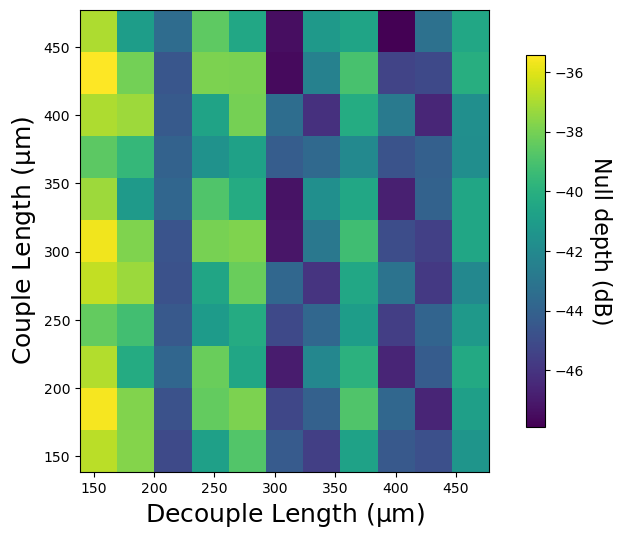

In [59]:
contrast = 10*np.log10(output_B)

fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(decoupleLengths, coupleLengths, contrast)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Null depth (dB)', rotation=270, labelpad=20, fontsize=16)
ax.set_xlabel("Decouple Length ($\mathrm{\mu}$m)", fontsize=18)
ax.set_ylabel("Couple Length ($\mathrm{\mu}$m)", fontsize=18)
plt.savefig('C:\\Users\\runner\\ActivePIC\\SoL_figs\\Tricoupler_2Layer_parameterSearch.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [59]:
10*np.log10(output_B[row_max, col_max])

-36.495412269005286

In [52]:
ind = np.argmin(output_B)
row_min, col_min = np.unravel_index(ind, np.shape(output_B))
print(f'Null depth: {10*np.log10(np.min(output_B)):0.2f} dB at couple length = {coupleLengths[row_min]} microns, decouple length = {decoupleLengths[col_min]} microns')

Null depth: -53.75 dB at couple length = 209.44 microns, decouple = 320.32 microns


In [57]:
ind = np.argmax(output_B)
row_max, col_max = np.unravel_index(ind, np.shape(output_B))
print(f'Exoplanet throughput: {np.max(output_B)*100:0.2f}% at couple length = {coupleLengths[row_max]} microns, decouple length = {decoupleLengths[col_max]} microns')

Exoplanet throughput: 78.36% at couple length = 154.0 microns, decouple = 190.96 microns


Plot throughput

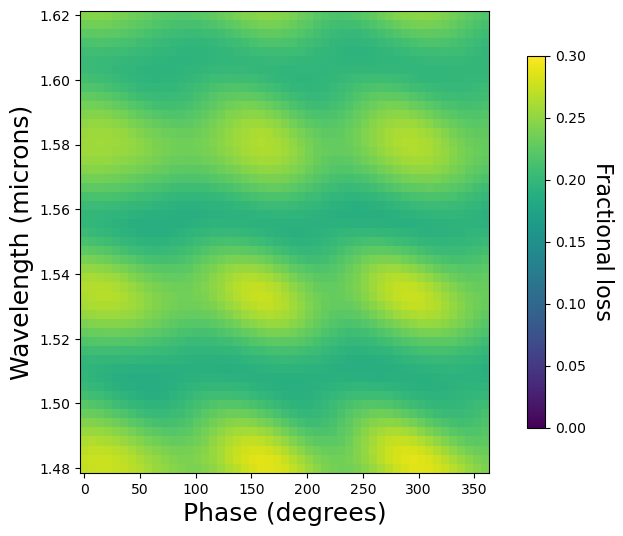

In [60]:
vmin, vmax = 0, 0.3
fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(phases, wavs, 1 - (output_A+output_B+output_C), vmin=vmin, vmax=vmax)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Fractional loss', rotation=270, labelpad=20, fontsize=16)
plt.xlabel(f"Phase (degrees)", fontsize=18)
plt.ylabel(f"Wavelength (microns)", fontsize=18)
plt.show()